<a href="https://colab.research.google.com/github/trantuan303/HM/blob/main/c1/baiolop/bai2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BMI kiểm tra: [23 38 22 33 25 26]
Nhãn thực tế: [0 1 0 1 0 0]
Xác suất mắc bệnh: [0.013 0.986 0.007 0.797 0.039 0.067]
Nhãn dự đoán: [0 1 0 1 0 0]

Độ chính xác: 100.0 %
Ma trận nhầm lẫn:
[[4 0]
 [0 2]]


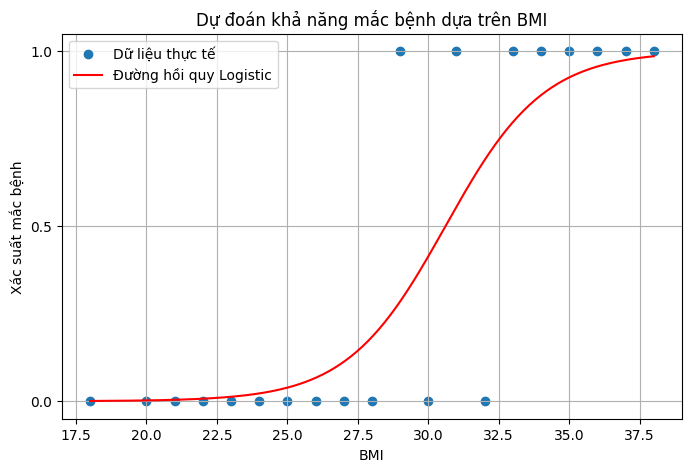

In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Tạo dữ liệu mẫu
BMI = np.array([
    18, 20, 21, 22, 23, 24, 25, 26, 27, 28,
    29, 30, 31, 32, 33, 34, 35, 36, 37, 38
])

# BMI càng cao thì khả năng mắc bệnh càng cao
MacBenh = np.array([
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
    1, 0, 1, 0, 1, 1, 1, 1, 1, 1
])

# Chuyển dữ liệu về dạng phù hợp cho mô hình
X = BMI.reshape(-1, 1)
y = MacBenh

# Chia dữ liệu thành tập huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 2. Xây dựng mô hình hồi quy Logistic
model = LogisticRegression()

# 3. Huấn luyện mô hình
model.fit(X_train, y_train)

# 4. Dự đoán xác suất và nhãn mắc bệnh
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

print("BMI kiểm tra:", X_test.flatten())
print("Nhãn thực tế:", y_test)
print("Xác suất mắc bệnh:", np.round(y_prob, 3))
print("Nhãn dự đoán:", y_pred)

# 5. Đánh giá mô hình
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("\nĐộ chính xác:", round(accuracy * 100, 2), "%")
print("Ma trận nhầm lẫn:")
print(cm)

# 6. Trực quan hóa dữ liệu và đường hồi quy Logistic
BMI_moi = np.linspace(18, 38, 200).reshape(-1, 1)
xac_suat = model.predict_proba(BMI_moi)[:, 1]

plt.figure(figsize=(8, 5))

plt.scatter(BMI, MacBenh, label="Dữ liệu thực tế")
plt.plot(BMI_moi, xac_suat, color="red",
         label="Đường hồi quy Logistic")

plt.xlabel("BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.title("Dự đoán khả năng mắc bệnh dựa trên BMI")
plt.yticks([0, 0.5, 1])
plt.legend()
plt.grid(True)
plt.show()
